# 3d — Baseline Accessibility Analysis: Hospitals, Costa Rica

## Purpose
Compute nearest-hospital travel times for the Costa Rican population and produce access-time figures.

Sinks are the **27 hospitals** of the official Costa Rican hospital register (`input_files/salud/hospitales_cr.shp`), not OSM. The primary-care EBAIS network (`input_files/salud/ebais_cr.shp`, 949 points) is deliberately *excluded*, so the numbers here are hospital access times, not general health-facility access times.

The earlier OSM-based version (`amenity=hospital` / `amenity=clinic`, 1 242 facilities) is kept in `3d_Baseline_Accesibility_Analysis-hospital_OSM_CR.ipynb`, which now writes to `figures/osm/` and to an `osm` Parquet/GDB path so the two runs do not overwrite each other.

## Inputs
| File | Description |
|------|-------------|
| `intermediate_results/gpkg/network/main_network_directed.gpkg` | Directed, AADT-attributed main road network produced in 1b (EPSG:8908, `fft` in hours) |
| `input_files/cri_pd_2020_1km_UNadj_ASCII_XYZ.csv` | WorldPop 2020 UN-adjusted 1 km population **density** grid (WGS84, people per km²) |
| `input_files/salud/hospitales_cr.shp` | Costa Rican hospital register — 27 geocoded points (WGS84), with `categoria` (Nacional / Especializado / Regional / Periférico) and a Google `place_id` per facility |

## Outputs
| File | Description |
|------|-------------|
| `figures/baseline_accessibility_hospitals.png` | Cumulative accessibility curve (population share vs. travel time) |
| `figures/hospital_access.png` | Map of nearest-hospital access times per 1 km population cell |
| `figures/hospital_access_chart.png` | Population distribution chart by access-time band |
| `intermediate_results/parquet/local_accessibility/hospital_accessibility_results.parquet` | Grid-cell access-time results (EPSG:8908) |
| `intermediate_results/parquet/local_accessibility/hospitals.parquet` | Hospital sink points (EPSG:8908) |
| `intermediate_results/database/local_accessibility/local_accessibility.gdb` | GDB layers: `hospital_accessibility_results`, `hospitals` |

## Key Processing Steps
1. **Load hospitals** — read the register shapefile, keep successfully geocoded (`estado == "OK"`) and de-duplicated records
2. **Load network** — read the directed main network from 1b and build an igraph graph (`fft` edge weights)
3. **Population grid** — convert WorldPop density to people per cell, snap each cell to the nearest network node
4. **Snap facilities** — nearest network node per hospital in the metric CRS
5. **Nearest-facility computation** — shortest-path travel time to the closest hospital for every cell
6. **Save results** — write Parquet and ArcGIS File Geodatabase layers in EPSG:8908
7. **Plot curve, map and chart** — cumulative access curve, spatial access-time map, population by access band

## Caveats
- Travel times are network times on the **main network only** (1b scope): population cells and hospitals snap to the nearest network node, so the first/last mile on local streets is not counted.
- With only 27 sinks the access times are substantially longer than the OSM run, which counted clinics/EBAIS as well — the two sets of figures are not comparable.
- The register covers CCSS public hospitals; private hospitals are not included.
- Coordinates come from Google Places geocoding of the facility name/address, so a point may sit at the site entrance or nearby rather than at the exact building.


In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

BASE_DIR = Path.cwd().parent  # notebook lives in /notebooks
sys.path.append(str(BASE_DIR))

from utils.accessibility_functions import (
    create_graph_for_spatial_matching,
    map_settlements_to_nodes_in_road_network,
    nearest_network_nodes,
    get_distance_to_nearest_facility,
    save_accessibility_results,
    plot_access_curve,
    plot_access_time_map,
)

In [2]:
# All paths are hard-coded here (no NetworkConfig) so they can be swapped one by one.
data_path = BASE_DIR / "input_files"
intermediate_path = BASE_DIR / "intermediate_results"

# Inputs
path_road_network = intermediate_path / "gpkg" / "network" / "main_network_directed.gpkg"  # from 1b
path_population = data_path / "cri_pd_2020_1km_UNadj_ASCII_XYZ.csv"  # WorldPop 1 km density grid
path_hospitals = data_path / "salud" / "hospitales_cr.shp"  # official hospital register (WGS84 points)

# Outputs
figure_dir = BASE_DIR / "figures"
parquet_dir = intermediate_path / "parquet" / "local_accessibility"
gdb_path = intermediate_path / "database" / "local_accessibility" / "local_accessibility.gdb"
output_crs = "EPSG:8908"  # CR-SIRGAS / CRTM05 (metres) — same working CRS as notebooks 1b/2

for p in (path_road_network, path_population, path_hospitals):
    if not p.exists():
        raise FileNotFoundError(
            f"Missing input: {p}\n"
            "If this path lives on OneDrive, make sure the folder is downloaded locally "
            "('Always keep on this device') — cloud placeholders cannot be opened."
        )

In [3]:
import geopandas as gpd
import pandas as pd

# Hospitals come from the official Costa Rican hospital register, geocoded with
# Google Places (one `place_id` per facility) and delivered as a WGS84 point
# shapefile. This replaces the OSM `amenity=hospital`/`clinic` extraction used in
# 3d_..._hospital_OSM_CR: the register is hospitals ONLY, so the primary-care
# EBAIS points in input_files/salud/ebais_cr.shp are not part of this run.
hospitals = gpd.read_file(path_hospitals)
assert hospitals.crs is not None and hospitals.crs.to_epsg() == 4326, (
    f"Expected EPSG:4326, found {hospitals.crs}"
)

# Keep only records whose geocoding resolved (`estado == "OK"`) and drop repeats
# of the same Google place (a hospital listed twice under different names).
n_raw = len(hospitals)
hospitals = hospitals[hospitals["estado"] == "OK"]
hospitals = hospitals.drop_duplicates(subset="place_id").reset_index(drop=True)

# `place_id` is the stable per-facility id used as the sink identifier below;
# `nombre_goo` is the Google-resolved name, `nombre_bus` the searched name.
hospitals["name"] = hospitals["nombre_goo"].fillna(hospitals["nombre_bus"])
hospitals = hospitals[["place_id", "name", "categoria", "direccion", "geometry"]]

# Longitude/Latitude columns to match the sink layout used by the Serbia inputs
hospitals["Longitude"] = hospitals.geometry.x
hospitals["Latitude"] = hospitals.geometry.y

print(f"{len(hospitals)} hospitals kept out of {n_raw} register records")
print(hospitals["categoria"].value_counts().to_string())
hospitals.head()

27 hospitals kept out of 27 register records
categoria
Periférico       10
Regional          8
Especializado     6
Nacional          3


,place_id,name,categoria,direccion,geometry,Longitude,Latitude
0,ChIJv7d9dFv7oI8RdYE_Vbaia1U,Hospital México,Nacional,"Opposite the General Cañas Highway, San José, ...",POINT (-84.11366 9.95213),-84.113658,9.952128
1,ChIJ3yG4Mn3joI8RsoRKKimIIXk,Hospital Dr. Rafael Ángel Calderón Guardia - CCSS,Nacional,"Avenidas 7 y 9, calles 15 y 17, C. 17, San Jos...",POINT (-84.06951 9.93675),-84.069509,9.936753
2,ChIJg_lLV1njoI8RO0rhKjjXg7A,Hospital San Juan de Dios,Nacional,"Paseo Colón y Avenida segunda, calles 14 y 16,...",POINT (-84.0851 9.93336),-84.085097,9.933362
3,ChIJlam7YFv7oI8R4slpFKuIoVM,Centro Nacional de Rehabilitación - CENARE.,Especializado,"San José, Alborada, Costa Rica",POINT (-84.1163 9.94852),-84.116299,9.948517
4,ChIJHTToDELjoI8RT7zNhXXQ_r8,Hospital Nacional de las Mujeres Adolfo Carit ...,Especializado,"WWF9+H62, C. Central Alfredo Volio, San José, ...",POINT (-84.08132 9.92391),-84.081317,9.923906


In [4]:
# Calibri is not installed on every machine (e.g. macOS); fall back quietly.
import matplotlib.font_manager as fm

if any(f.name == "Calibri" for f in fm.fontManager.ttflist):
    plt.rcParams["font.family"] = "Calibri"

In [5]:
# Build graph + nodes, snap population grid, snap facilities, compute nearest access time
base_network = gpd.read_file(path_road_network, layer="main_network_directed")
assert base_network.crs is not None and base_network.crs.to_epsg() == 8908, (
    f"Expected EPSG:8908, found {base_network.crs}"
)
missing = {"from_id", "to_id", "id", "fft"} - set(base_network.columns)
assert not missing, f"Network is missing required columns: {missing}"

nodes, graph = create_graph_for_spatial_matching(base_network)

# WorldPop 1 km grid: Z is population DENSITY (people per km²), so convert to
# people per cell with the latitude-dependent 30-arc-second cell area.
df_worldpop = pd.read_csv(path_population).rename(columns={"Z": "density"})
df_worldpop = df_worldpop[df_worldpop["density"] > 0].reset_index(drop=True)
cell_deg = 1 / 120  # 30 arc-seconds
cell_area_km2 = (111.320 * np.cos(np.radians(df_worldpop["Y"])) * cell_deg) * (
    110.574 * cell_deg
)
df_worldpop["population"] = df_worldpop["density"] * cell_area_km2
df_worldpop = gpd.GeoDataFrame(
    df_worldpop,
    geometry=gpd.points_from_xy(df_worldpop["X"], df_worldpop["Y"]),
    crs="EPSG:4326",
).to_crs(base_network.crs)
print(
    f"Population cells: {len(df_worldpop):,} | "
    f"total population: {df_worldpop['population'].sum():,.0f}"
)

df_worldpop = map_settlements_to_nodes_in_road_network(df_worldpop, nodes)

# Snap the register hospitals (EPSG:4326) to the network in the metric CRS
sink_hospitals = hospitals.to_crs(base_network.crs)
nearest_network_nodes(sink_hospitals, nodes)

# Nearest hospital for each population cell (slow step). The shared helper names
# its output columns closest_sink_osm_id/... regardless of the id column used —
# here that column holds the register's Google `place_id`.
df_worldpop = get_distance_to_nearest_facility(
    df_worldpop, sink_hospitals, graph, id_col="place_id"
)

# The closest_sink_* columns come back as object dtype; make them file-format safe
df_worldpop["closest_sink_total_fft"] = pd.to_numeric(
    df_worldpop["closest_sink_total_fft"], errors="coerce"
)
df_worldpop["closest_sink_vertex_id"] = pd.to_numeric(
    df_worldpop["closest_sink_vertex_id"], errors="coerce"
)
df_worldpop["closest_sink_osm_id"] = df_worldpop["closest_sink_osm_id"].astype(str)

100%|██████████| 9764/9764 [00:00<00:00, 27550.09it/s]


Population cells: 62,053 | total population: 5,137,882


100%|██████████| 27/27 [00:00<00:00, 6389.07it/s]


In [6]:
# Save results (Parquet + ArcGIS File Geodatabase, in the chosen output CRS)
save_accessibility_results(
    df_worldpop, sink_hospitals, "hospitals", parquet_dir, gdb_path, output_crs
)

Saved hospital_accessibility_results -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/parquet/local_accessibility/hospital_accessibility_results.parquet
Saved hospital_accessibility_results -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/database/local_accessibility/local_accessibility.gdb (layer 'hospital_accessibility_results')
Saved hospitals -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/parquet/local_accessibility/hospitals.parquet
Saved hospitals -> /Users/joeldeplaen/Library/CloudStorage/OneDrive-VrijeUniversiteitAmsterdam/Documents/GitHub/Criticality-Analysis-CR/intermediate_results/database/local_accessibility/local_accessibility.gdb (layer 'hospitals')


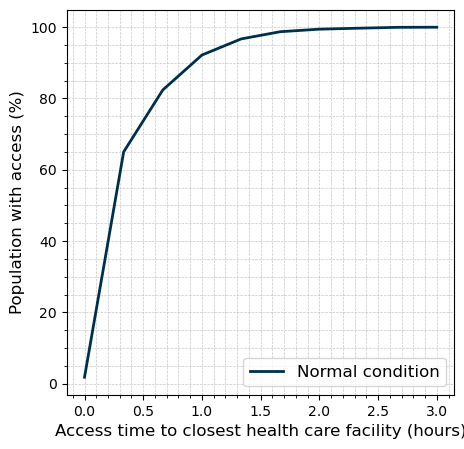

In [7]:
plot_access_curve(df_worldpop, "hospitals", figure_dir)

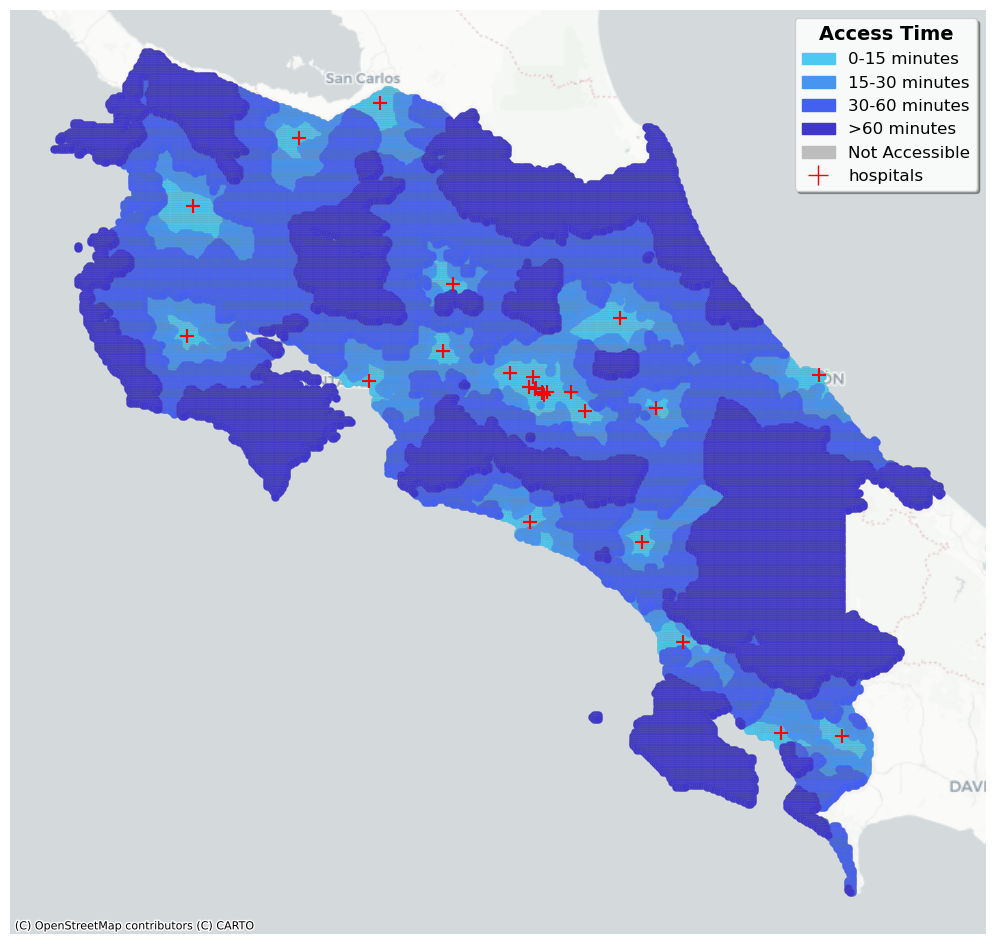

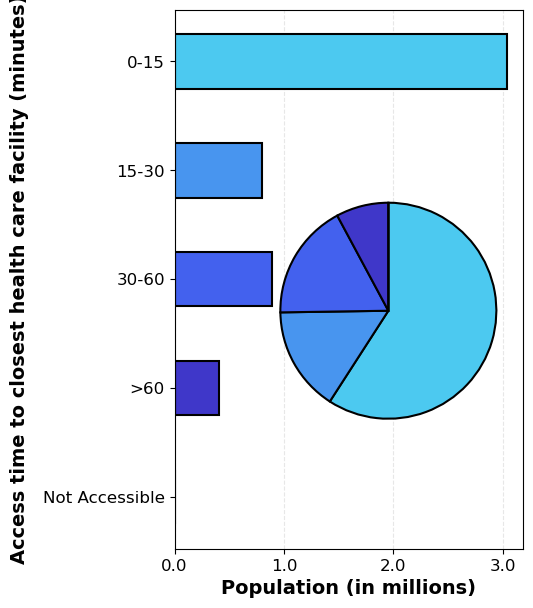

In [8]:
def plot_accessibility_chart_cr(df_worldpop_plot, figure_dir, show=True):
    """
    Costa Rica variant of utils' plot_accessibility_chart.

    The generic chart reindexes on hour-based categories ("60-90", ">120", ...)
    that plot_access_time_map does not produce, silently dropping the ">60" and
    "Not Accessible" population. This variant uses the exact categories and
    colours of the map so the two figures agree.
    """
    category_order = ["0-15", "15-30", "30-60", ">60", "Not Accessible"]
    category_colors = ["#4cc9f0", "#4895ef", "#4361ee", "#3f37c9", "#bdbdbd"]
    color_dict = dict(zip(category_order, category_colors))

    pop_by_category = (
        df_worldpop_plot.groupby("category")["population"].sum() / 1e6
    ).reindex(category_order, fill_value=0)
    pop_by_category_reversed = pop_by_category[::-1]

    fig, ax = plt.subplots(figsize=(4.5, 7))
    ax.barh(
        range(len(pop_by_category_reversed)),
        pop_by_category_reversed.values,
        height=0.5,
        color=[color_dict[cat] for cat in pop_by_category_reversed.index],
        edgecolor="black",
        linewidth=1.5,
    )
    ax.set_ylabel(
        "Access time to closest health care facility (minutes)",
        fontsize=14,
        fontweight="bold",
        labelpad=10,
    )
    ax.set_xlabel("Population (in millions)", fontsize=14, fontweight="bold")
    ax.set_yticks(range(len(pop_by_category_reversed)))
    ax.set_yticklabels(pop_by_category_reversed.index, fontsize=12)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda x, p: f"{x:.1f}"))
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(axis="x", alpha=0.3, linestyle="--")
    ax.set_axisbelow(True)

    # Inset pie chart, same order and colours as the bars
    ax_inset = fig.add_axes([0.3, 0.15, 0.6, 0.6])
    ax_inset.pie(
        pop_by_category.values,
        colors=[color_dict[cat] for cat in pop_by_category.index],
        startangle=90,
        counterclock=False,
        wedgeprops={"edgecolor": "black", "linewidth": 1.5},
    )

    figure_dir.mkdir(parents=True, exist_ok=True)
    plt.savefig(figure_dir / "hospital_access_chart.png", dpi=200, bbox_inches="tight")
    if show:
        plt.show()


# Access-time map + population distribution chart
df_worldpop_plot = plot_access_time_map(
    df_worldpop, sink_hospitals, "hospitals", figure_dir
)
plot_accessibility_chart_cr(df_worldpop_plot, figure_dir)